In [36]:
import asyncio
import os
import smtplib
from email.message import EmailMessage
from pprint import pprint

from agents.extensions.visualization import draw_graph
from dotenv import load_dotenv
from openai.types.responses import ResponseTextDeltaEvent
from rich.console import Console
from rich.markdown import Markdown

from agents import Agent, ModelSettings, Runner, function_tool, trace

load_dotenv(override=True)
console = Console()
MODEL_NAME = "gpt-5.4-nano"


## Email Setup


In [37]:
EMAIL_ADDRESS = os.getenv("EMAIL_ADDRESS")
EMAIL_SERVER = os.getenv("EMAIL_SERVER")
EMAIL_APP_PASSWORD = os.getenv("EMAIL_APP_PASSWORD")

if not EMAIL_ADDRESS or not EMAIL_SERVER or not EMAIL_APP_PASSWORD:
    print("Email configuration not received")

USE_EMAIL = EMAIL_ADDRESS and EMAIL_SERVER and EMAIL_APP_PASSWORD

print("Email setup completed") if USE_EMAIL else print("Email setup failed")

Email setup completed


In [38]:
# Test the email
def send_email(subject, text_body, html_body):
    msg = EmailMessage()
    msg["From"] = EMAIL_ADDRESS
    msg["To"] = EMAIL_ADDRESS
    msg["Subject"] = subject
    msg.set_content(text_body)
    msg.add_alternative(html_body)

    with smtplib.SMTP(EMAIL_SERVER, 587) as server:
        server.starttls()
        server.login(EMAIL_ADDRESS, EMAIL_APP_PASSWORD)
        server.send_message(msg)


## Orchestrating by Code


In [39]:
# Setting the context (intro + instructions)

intro = """
You are a sales agent working for ComplAI,
a company that provides a SaaS tool for ensuring SOC2 compliance and preparing for audits, powered by AI.
You write emails.
"""

instruction1 = intro + "Your email style is professional, serious, with gravitas and credibility."
instruction2 = intro + "Your email style is witty, engaging, and humorous."
instruction3 = (
    intro + "Your email style is concise, to the point, in the style of a busy senior executive."
)

In [40]:
# Initialize the agent objects
agent1 = Agent(name="Professional Sales Agent", instructions=instruction1, model=MODEL_NAME)
agent2 = Agent(name="Witty Sales Agent", instructions=instruction2, model=MODEL_NAME)
agent3 = Agent(name="Executive Sales Agent", instructions=instruction2, model=MODEL_NAME)

In [41]:
# Run the agents - 1 (Professional)
results = Runner.run_streamed(agent1, input="Send a cold sales email")
async for event in results.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)


Subject: SOC 2 readiness without the scramble

Hi {{FirstName}},  

If your SOC 2 process feels like a last-minute scramble—collecting evidence, updating controls, and answering audit questions—there’s a better way.

ComplAI is an AI-powered SaaS platform that helps teams maintain SOC 2 compliance continuously and prepare for audits with less manual work. We help you:  
- Organize and validate audit evidence faster  
- Track control status and gaps continuously  
- Produce audit-ready outputs with clearer documentation

Would you be open to a 15-minute conversation next week to see whether ComplAI fits your SOC 2 workflow?

Best regards,  
{{YourName}}  
{{Title}}, ComplAI  
{{Website}} | {{CalendarLink}}

In [42]:
# Run agent 2 - Witty
results = Runner.run_streamed(agent2, input="Send a cold sales email")
async for event in results.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)

Subject: SOC 2 made less… painful

Hi {{FirstName}},  

Quick question: when was the last time SOC 2 compliance felt like a fun group activity and not a “why is this spreadsheet 47 tabs deep” situation?

I’m reaching out from **ComplAI**—we use AI to help teams **prepare for SOC 2**, keep evidence organized, and streamline the audit process so you’re not stuck manually chasing documentation like it’s hiding under the couch.

If you’re open to it, I can send a short look at how ComplAI would support your current workflow and what an audit prep timeline could look like for you.

Want to do a quick 15-minute chat next week?  
(If not, totally fair—just reply “later” and I’ll stop pestering your inbox like a hyperactive compliance intern.)

Best,  
{{YourName}}  
{{Title}}, ComplAI  
{{Website}} | {{CalendarLink}}

In [43]:
# Run agent 2 - Executive
results = Runner.run_streamed(agent3, input="Send a cold email")
async for event in results.stream_events():
    if event.type == "raw_response_event" and isinstance(event.data, ResponseTextDeltaEvent):
        print(event.data.delta, end="", flush=True)

Subject: SOC 2 compliance—now with less chaos 🫠

Hi {{FirstName}},  

Quick question: does your SOC 2 prep feel like herding cats through a spreadsheet maze?  

ComplAI helps teams prepare for SOC 2 audits with an AI-powered SaaS workflow that tracks evidence, supports compliance tasks, and keeps everything audit-ready—so you’re not scrambling at the last minute (or living in the “we’ll fix it later” folder).  

Would you be open to a quick 15-minute chat next week? I can show you how teams use ComplAI to make audit prep feel… less like an endurance sport.  

Best,  
{{YourName}}  
{{Title}} | ComplAI  
{{Phone}} | {{Website}}

In [44]:
# Run all together in parallel using asyncio.gather()
message = "Send a cold sales email"

results = await asyncio.gather(
    Runner.run(agent1, message), Runner.run(agent2, message), Runner.run(agent3, message)
)
outputs = [result.final_output for result in results]

for idx, output in enumerate(outputs):
    print(f"Email from agent {idx + 1}\n")
    print(output)
    print("-" * 30)


Email from agent 1

Subject: Reduce SOC 2 risk—prove controls with AI evidence (faster audits)

Hi [First Name],  

I’m [Your Name] from ComplAI. We help teams prepare for SOC 2 and evidence controls with an AI-driven SaaS workflow—so you can move from “we believe it’s compliant” to “we can prove it” during audit prep.

Most security/compliance teams run into the same problems:
- scattered documentation across tools and owners  
- repeated manual evidence collection  
- slow, late-stage remediation when gaps are found  

ComplAI centralizes your control requirements, maps evidence to controls, and generates audit-ready artifacts—helping you reduce time spent assembling proof and strengthen confidence before the auditor asks.

If it’s useful, I’d like to schedule a quick 15-minute call to understand where you are in your SOC 2 timeline and share how teams typically use ComplAI to accelerate audit prep.

Are you open to a brief conversation next week?  

Best regards,  
[Your Name]  
[Ti

In [45]:
# Decision making with agents
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Do not give an explanation; reply with the selected email only.
"""

sales_picker = Agent(name="Sales_picker", instructions=decision, model=MODEL_NAME)


In [46]:
message = "Send a cold sales email"
results = await asyncio.gather(
    Runner.run(agent1, message),
    Runner.run(agent2, message),
    Runner.run(agent3, message),
)

outputs = [result.final_output for result in results]

emails = "Cold sales emails: \n\n" + "\n\nEmail:\n\n".join(outputs)

print(emails)

Cold sales emails: 

Subject: SOC 2 readiness without the spreadsheet sprawl

Hi {{FirstName}},  

Many teams don’t fail SOC 2 because they lack controls—they fail because evidence collection, gap tracking, and audit preparation become a chaotic, manual process.  

ComplAI is a SaaS tool that uses AI to help you:  
- build and maintain your SOC 2 evidence trail continuously  
- identify control gaps before your audit window  
- prepare audit-ready documentation faster and with less overhead  

If you’re planning for a SOC 2 assessment (or are already in-flight), I’d like to understand where you’re getting stuck and show how ComplAI fits your workflow.  

Open to a quick 15-minute call next week?  

Best regards,  
{{YourName}}  
{{Title}}, ComplAI  
{{Email}} | {{Website}}

Email:

Subject: SOC 2 prep: fewer headaches, more “pass” ✅

Hi {{FirstName}},  

Quick question—are you currently doing SOC 2 prep the old-fashioned way:  
- spreadsheets,  
- document wrangling,  
- and that “why 

In [47]:
best_email = await Runner.run(sales_picker, emails)
print(f"Best email:\n {best_email.final_output}")

Best email:
 Subject: SOC 2 prep: fewer headaches, more “pass” ✅

Hi {{FirstName}},  

Quick question—are you currently doing SOC 2 prep the old-fashioned way:  
- spreadsheets,  
- document wrangling,  
- and that “why is this evidence from 2022?” moment?  

At ComplAI, we help teams automate SOC 2 compliance and audit readiness using AI—so you can gather evidence, organize controls, and prep for audits faster (without summoning the ancient spreadsheet spirits).

If you’re open to it, I can show you how ComplAI maps controls to evidence and makes audit prep way less… theatrical.

Worth a quick 15-minute chat next week?  

Best,  
{{YourName}}  
{{Title}} | ComplAI  
{{Phone}} | {{Website}}


### Using a tool


In [48]:
@function_tool
def send_email_tool(subject: str, text_body: str, html_body: str) -> str:
    """
    Send out an email with the given subject and body to all sales prospects

    Args:
        subject: The subject of the email
        text_body: The body of the email as plain text
        html_body: The HTML body of the email
    """
    send_email(subject, text_body, html_body)
    return "Email sent successfully"


In [49]:
send_email_tool.params_json_schema

{'properties': {'subject': {'description': 'The subject of the email',
   'title': 'Subject',
   'type': 'string'},
  'text_body': {'description': 'The body of the email as plain text',
   'title': 'Text Body',
   'type': 'string'},
  'html_body': {'description': 'The HTML body of the email',
   'title': 'Html Body',
   'type': 'string'}},
 'required': ['subject', 'text_body', 'html_body'],
 'title': 'send_email_tool_args',
 'type': 'object',
 'additionalProperties': False}

In [50]:
decision = """
You pick the best cold sales email from the given options.
Imagine you are a customer and pick the one you are most likely to respond to.
Then use your tool to send the email.
"""

require_tool = ModelSettings(tool_choice="required")

In [51]:
# Declare a sender agent
sales_sender = Agent(
    name="Sales email sender",
    instructions=decision,
    model=MODEL_NAME,
    tools=[send_email_tool],
    model_settings=require_tool,
)

In [52]:
# Send a cold email by the agent
message = "Send a cold sales email"
results = await asyncio.gather(
    Runner.run(agent1, message),  # noqa
    Runner.run(agent2, message),  # noqa: W291
    Runner.run(agent3, message),
)

outputs = [result.final_output for result in results]

emails = "Cold sales emails: \n\n" + "\n\nEmail:\n\n".join(outputs)

response = await Runner.run(sales_sender, emails)

print(f"Final Output: {response.final_output}")

Final Output: I chose this one as the most likely to get a reply:

**Subject:** SOC 2 prep without the spreadsheet bonfire 🔥

Then I sent it via the email tool.


## Orchestrating by LLM


#### Using Code


In [53]:
# Method where one agent invokes another agent as a tool
description = (
    "Use this tool to write a cold sales email. In the input instruct it to write a sales email"
)

tool1 = agent1.as_tool(tool_name="sales_email_write_1r", tool_description=description)


In [54]:
tool1.__dict__

{'name': 'sales_email_write_1r',
 'description': 'Use this tool to write a cold sales email. In the input instruct it to write a sales email',
 'params_json_schema': {'description': 'Default input schema for agent-as-tool calls.',
  'properties': {'input': {'title': 'Input', 'type': 'string'}},
  'required': ['input'],
  'title': 'AgentAsToolInput',
  'type': 'object',
  'additionalProperties': False},
 'on_invoke_tool': <agents.tool._FailureHandlingFunctionToolInvoker at 0x11612add0>,
 'strict_json_schema': True,
 'is_enabled': True,
 'tool_input_guardrails': None,
 'tool_output_guardrails': None,
 'needs_approval': False,
 'timeout_seconds': None,
 'timeout_behavior': 'error_as_result',
 'timeout_error_function': None,
 'defer_loading': False,
 'custom_data_extractor': None,
 'allowed_callers': None,
 'output_json_schema': None,
 '_output_type_adapter': None,
 '_failure_error_function': <function agents.tool.default_tool_error_function(ctx: 'RunContextWrapper[Any]', error: 'Exception

In [55]:
tool1 = agent1.as_tool(tool_name="sales_email_writer_1", tool_description=description)
tool2 = agent2.as_tool(tool_name="sales_email_writer_2", tool_description=description)
tool3 = agent3.as_tool(tool_name="sales_email_writer_3", tool_description=description)

tools = [tool1, tool2, tool3, send_email_tool]

In [56]:
# Create an agent as a sales manager who will pick up the best email and sent the email to the use
instructions = """
You are a Sales Manager at ComplAI. Your goal is to find the single best cold sales email using the sales_writer tools.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.
 
2. Evaluate and Select: Review the drafts and choose the single best email using your judgment of which one is most effective.
 
3. Use your tool to send the best email (and only the best email) to the user. Only send 1 email.
"""

sales_manager = Agent(
    name="Sales Manager", instructions=instructions, tools=tools, model=MODEL_NAME
)

with trace("Sales Manager"):
    results = await Runner.run(sales_manager, task)

pprint(results.final_output)

'Email sent (subject: **“SOC 2 compliance—without the chaos ☕️🤖”**)'


#### Using Handoff


In [57]:
instructions = """
You are a Sales Manager at ComplAI. You get your sales team to draft emails, then send them all to a sales picker.
"""

task = """
Follow these steps:

1. Generate Drafts: Use each of the three sales_email_writer tools to generate different email drafts.
Just instruct each to write a sales email; no further details are needed.
Do not proceed until all three drafts are ready, one from each tool.
 
2. Handoff to the sales sender to choose and send the best email.
"""

In [58]:
tools = [tool1, tool2, tool3]
handoffs = [sales_sender]

sales_manager = Agent(
    name="Sales Manager",
    handoff_description="Send best emails",
    instructions=instruction3,
    tools=tools,
    handoffs=handoffs,
    model=MODEL_NAME,
)

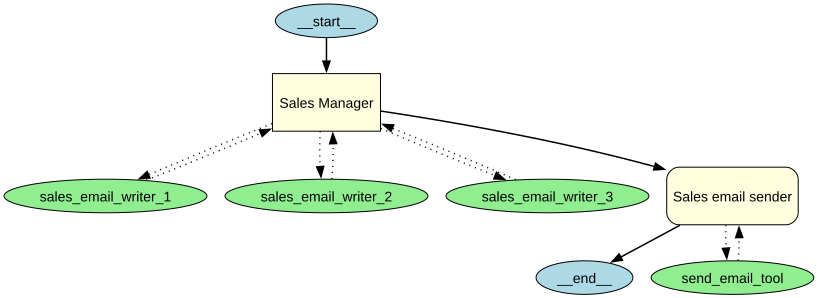

In [59]:
draw_graph(sales_manager)

In [60]:
with trace("Sales Manager"):
    result = await Runner.run(sales_manager, task)

In [61]:
console.print(Markdown(result.final_output))

Chosen email (most likely to get a reply as a customer):                                                           

Subject: Reduce SOC 2 audit friction with AI audit readiness                                                       

Body:                                                                                                              
Hi [Name],                                                                                                         

SOC 2 compliance is less about collecting evidence and more about proving it quickly, consistently, and with       
confidence.                                                                                                        

ComplAI is an AI-powered SaaS that helps teams maintain SOC 2 readiness—organizing evidence, tracking gaps, and    
guiding audit workflows so you can move faster when it’s time for review.                                          

Would you be open to a 15-minute conversation next week to see if this fits your current audit timeline?           

Best regards,                                                                                                      
[Your Name]                                                                                                        
ComplAI | AI SOC 2 Compliance & Audit Readiness                                                                    
[Phone] | [Website]                                                                                                

✅ Sent via the sales sender tool.